## Lab 6
## Name: Arnish Manwatkar
## Batch: C-C3
## Roll no: 38

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [20]:
df=pd.read_csv('seeds_new.csv')

In [21]:
df=df.dropna(axis=1,how="all")

In [22]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [23]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [24]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [26]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [27]:
df.shape

(210, 8)

In [28]:
df.dtypes

Area                       float64
Perimeter                  float64
Compactness                float64
Length of kernel           float64
Width of kernel            float64
Asymmetry coefficient      float64
Length of kernel groove    float64
Class (1, 2, 3)              int64
dtype: object

In [29]:
df.isnull().sum()

Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
Class (1, 2, 3)            0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

## Univarient Analysis

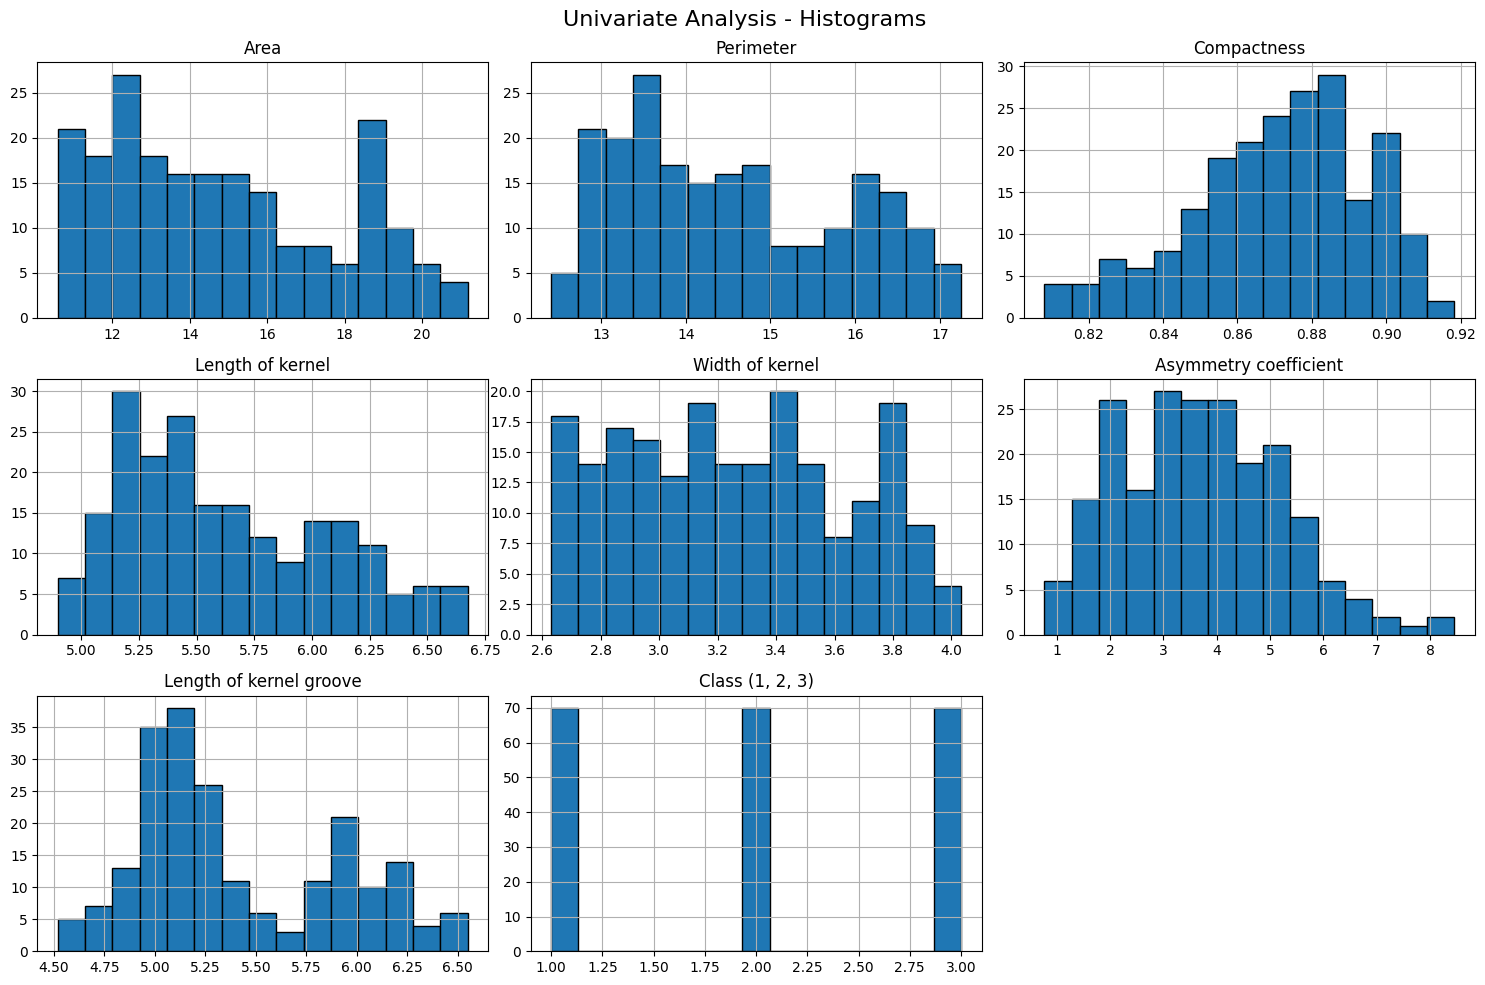

In [32]:
num_cols = df.select_dtypes(include='number').columns

df[num_cols].hist(figsize=(15, 10), bins=15, edgecolor='black')
plt.suptitle("Univariate Analysis - Histograms", fontsize=16)
plt.tight_layout()
plt.show()

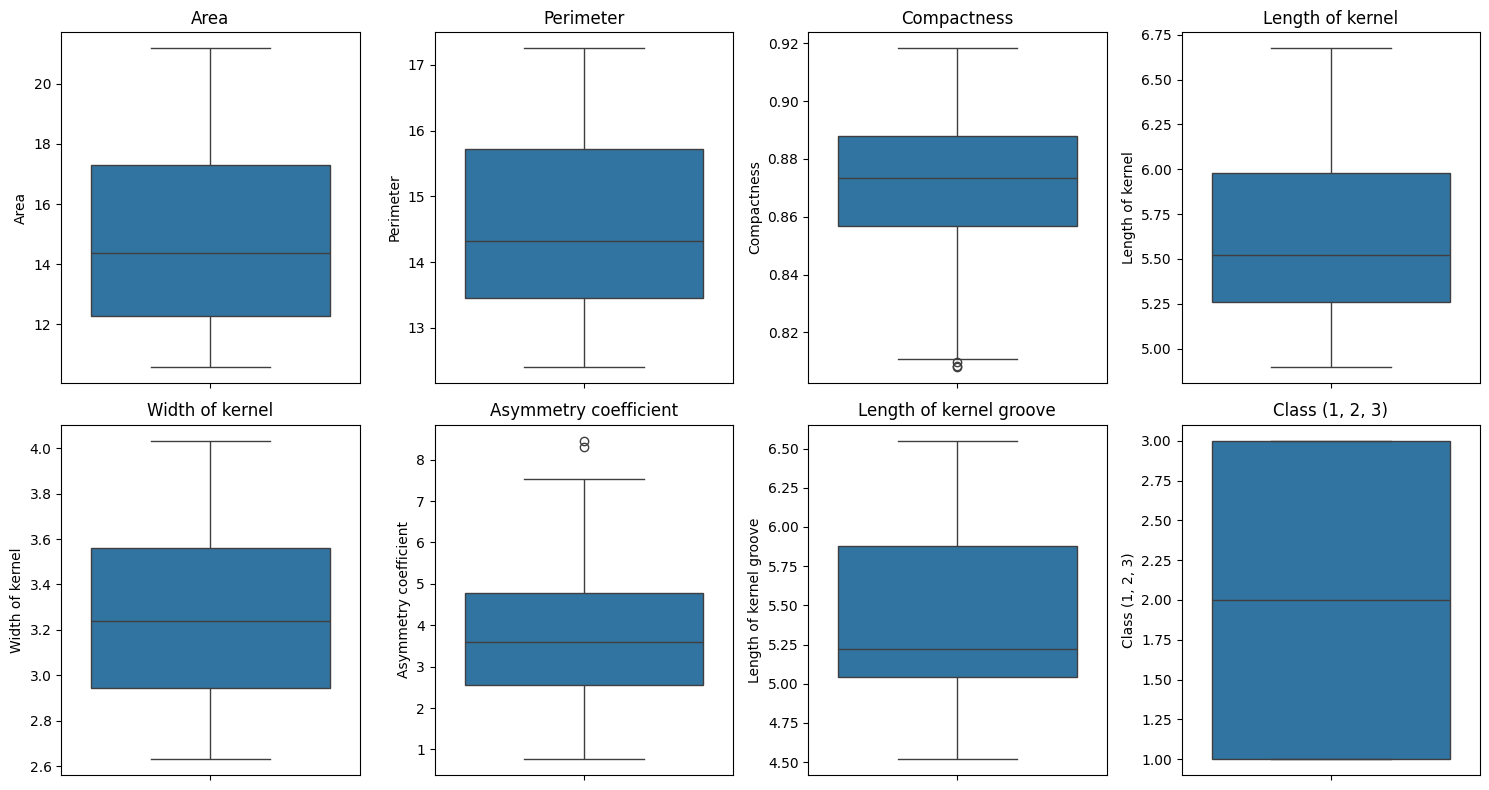

In [33]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

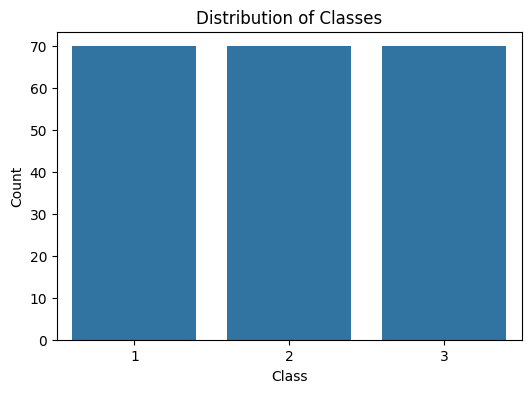

In [34]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class (1, 2, 3)', data=df)
plt.title("Distribution of Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

## Bivarient Analysis

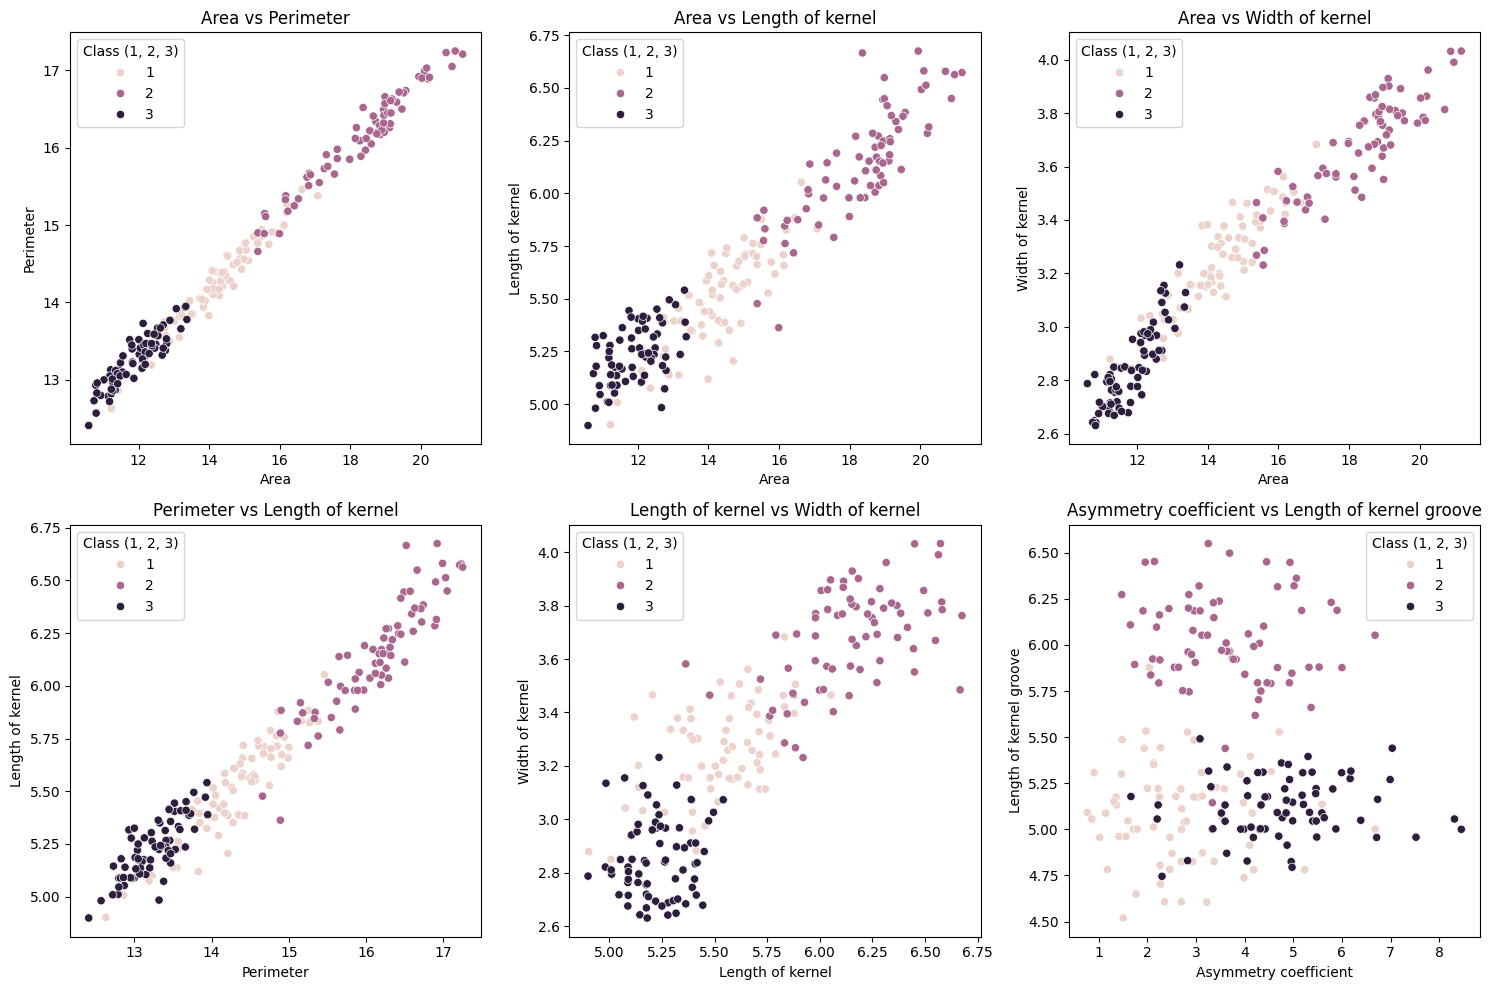

In [35]:
plt.figure(figsize=(15, 10))

features = [
    'Area',
    'Perimeter',
    'Compactness',
    'Length of kernel',
    'Width of kernel',
    'Asymmetry coefficient',
    'Length of kernel groove'
]

pairs = [
    ('Area', 'Perimeter'),
    ('Area', 'Length of kernel'),
    ('Area', 'Width of kernel'),
    ('Perimeter', 'Length of kernel'),
    ('Length of kernel', 'Width of kernel'),
    ('Asymmetry coefficient', 'Length of kernel groove')
]

for i, (x, y) in enumerate(pairs, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue='Class (1, 2, 3)'
    )
    plt.title(f'{x} vs {y}')

plt.tight_layout()
plt.show()

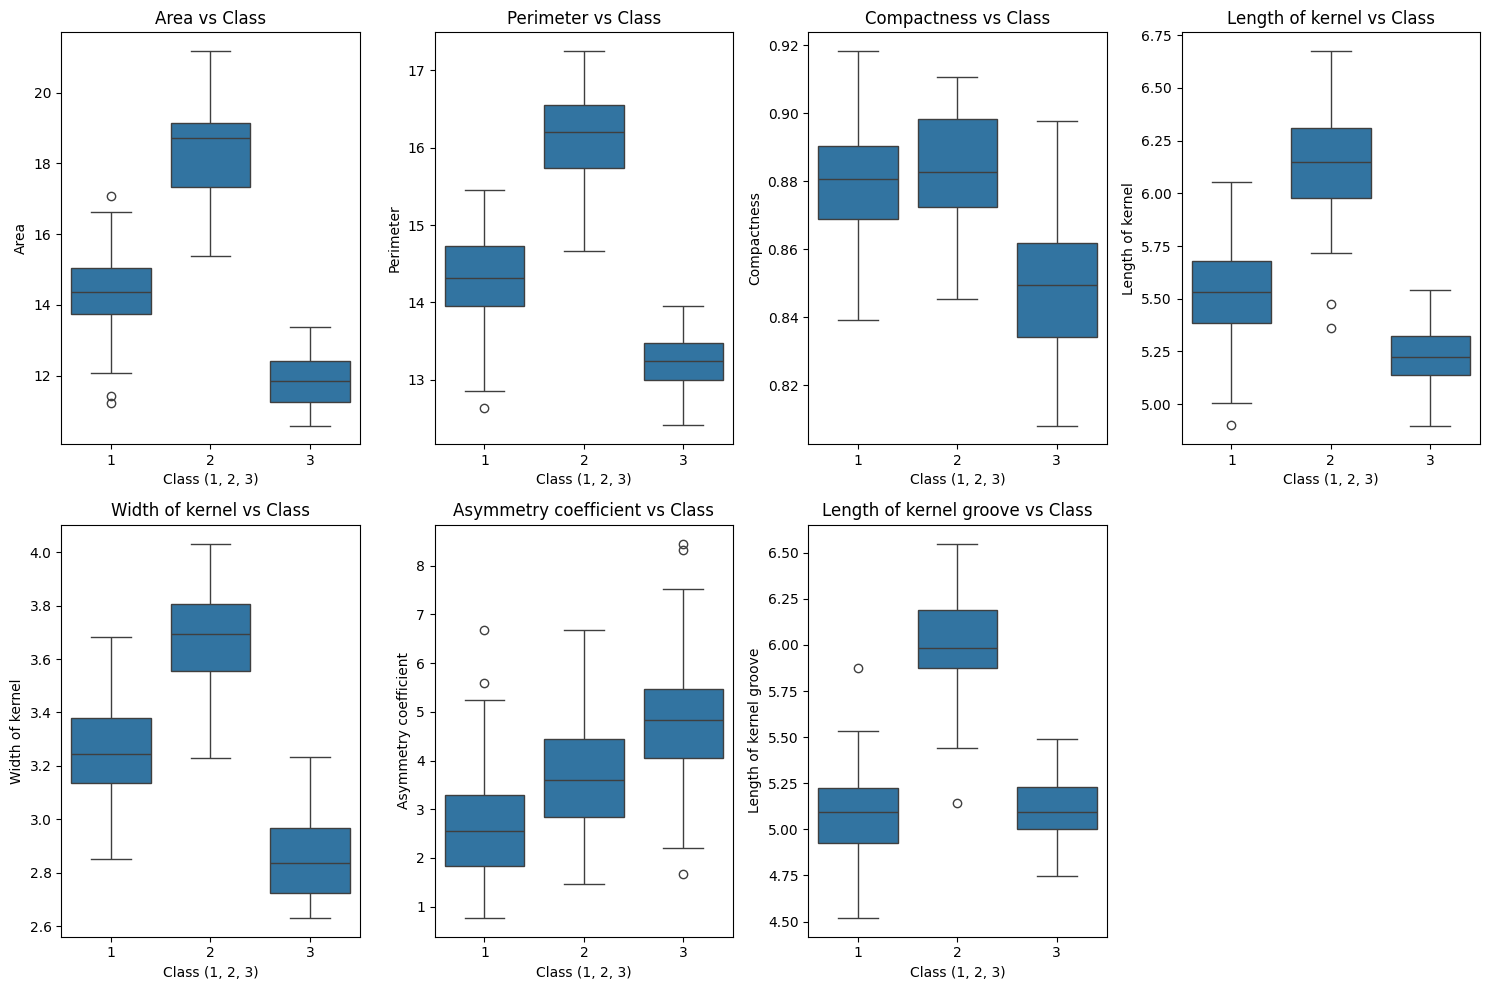

In [36]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(features, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(
        data=df,
        x='Class (1, 2, 3)',
        y=col
    )
    plt.title(f'{col} vs Class')

plt.tight_layout()
plt.show()

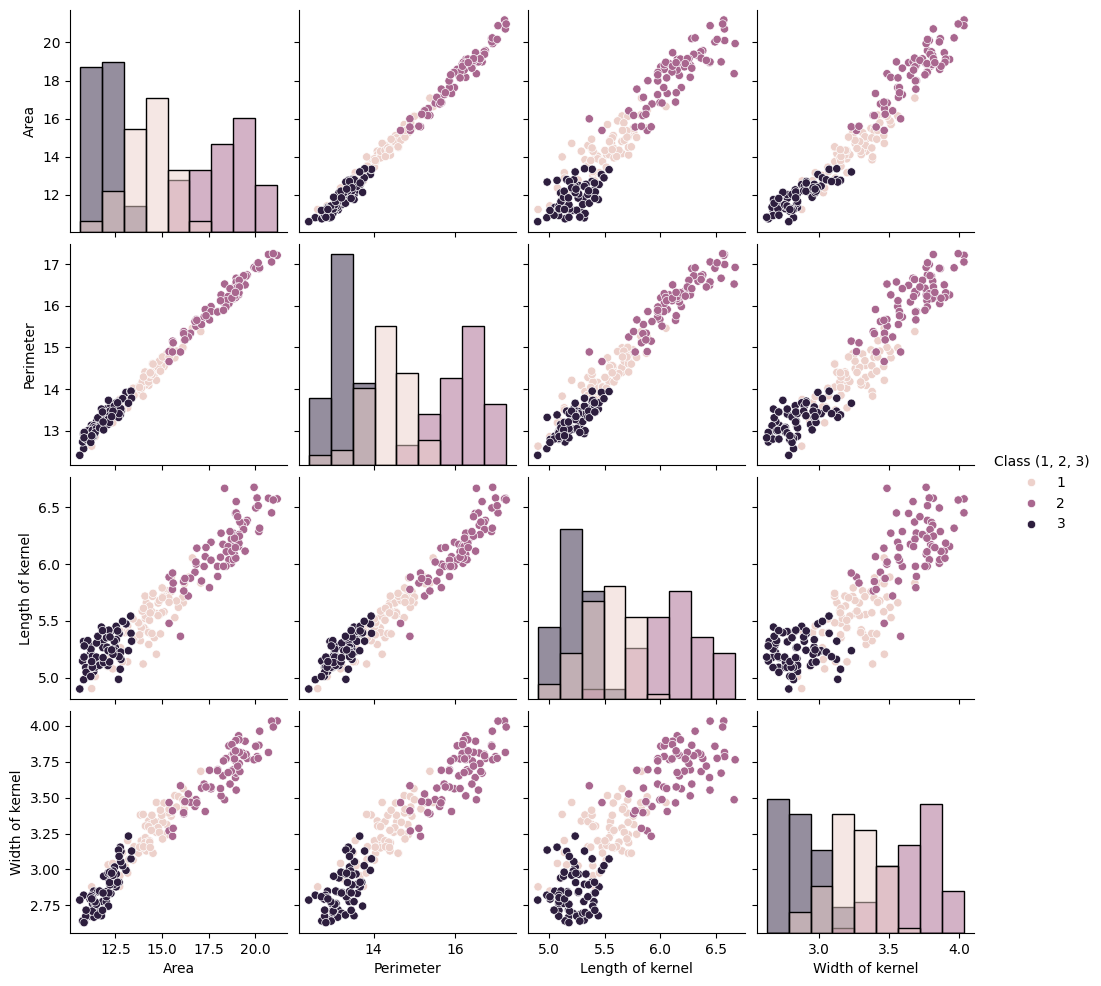

In [38]:
sns.pairplot(
    df,
    vars=[
        'Area',
        'Perimeter',
        'Length of kernel',
        'Width of kernel'
    ],
    hue='Class (1, 2, 3)',
    diag_kind='hist'
)

plt.show()

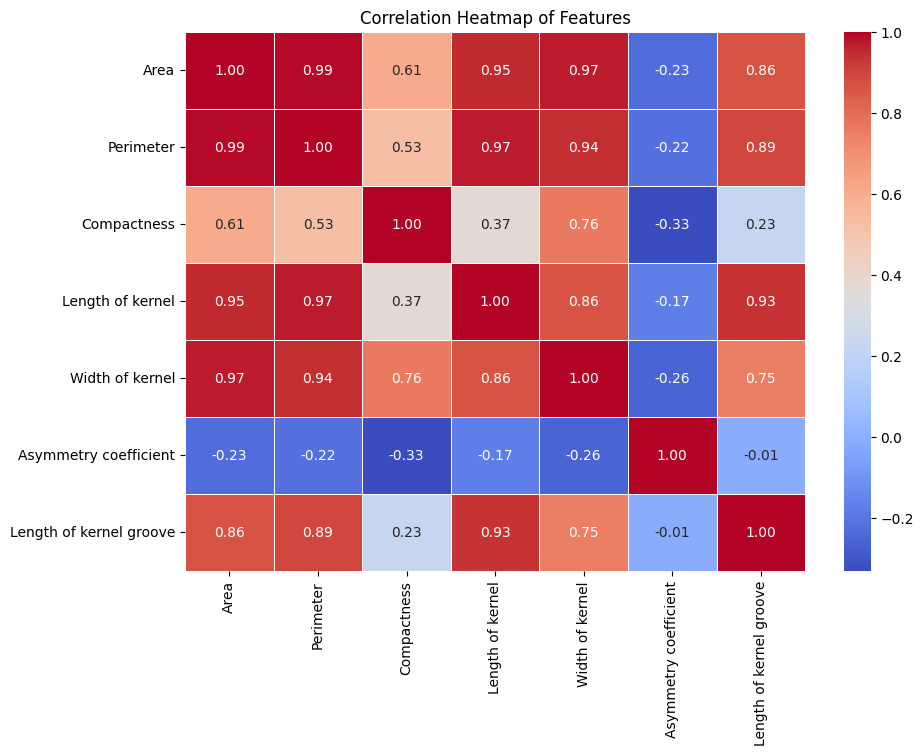

In [40]:
features = [
    'Area',
    'Perimeter',
    'Compactness',
    'Length of kernel',
    'Width of kernel',
    'Asymmetry coefficient',
    'Length of kernel groove'
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Features")
plt.show()

## ALgorithm

In [41]:
X = df.drop('Class (1, 2, 3)',axis=1)
y_original=df['Class (1, 2, 3)']

print("Input Shape",X.shape)
print("Target Shape",y_original.shape)

Input Shape (210, 7)
Target Shape (210,)


In [42]:
y = y_original-1

print("Original Classes:")
print(sorted(y_original.unique()))
print("\n ANN encoded classes:")
print(sorted(y.unique()))

Original Classes:
[np.int64(1), np.int64(2), np.int64(3)]

 ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training Sample:", X_train.shape[0])
print("Testing Sample:", X_test.shape[0])

Training Sample: 168
Testing Sample: 42


In [44]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [47]:
print("First 5 scaled training samples:")
print(X_train[:5])

First 5 scaled training samples:
      Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
178  11.48      13.05       0.8473             5.180            2.758   
62   12.36      13.19       0.8923             5.076            3.042   
54   14.52      14.60       0.8557             5.741            3.113   
164  11.14      12.79       0.8558             5.011            2.794   
207  13.20      13.66       0.8883             5.236            3.232   

     Asymmetry coefficient  Length of kernel groove  
178                  5.876                    5.002  
62                   3.220                    4.605  
54                   1.481                    5.487  
164                  6.388                    5.049  
207                  8.315                    5.056  


In [48]:
model = Sequential([
  Input(shape=(7,)),
  Dense(16, activation='relu'),
  Dense(8, activation='relu'),
  Dense(3, activation='softmax')
])

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [51]:
loss = "sparse_categorical_crossentropy"

In [52]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [53]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    batch_size=16,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4627 - loss: 2.3736 - val_accuracy: 0.4706 - val_loss: 2.4522
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4478 - loss: 1.8895 - val_accuracy: 0.3824 - val_loss: 2.0682
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3731 - loss: 1.6473 - val_accuracy: 0.3824 - val_loss: 1.7515
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4254 - loss: 1.4173 - val_accuracy: 0.4412 - val_loss: 1.5150
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5970 - loss: 1.2432 - val_accuracy: 0.4412 - val_loss: 1.3721
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6418 - loss: 1.1482 - val_accuracy: 0.4118 - val_loss: 1.2343
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5970 - loss: 1.0700 - val_accuracy: 0.4412 - val_loss: 1.1304
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5672 - loss: 1.0160 - val_accuracy: 0.4412 - val_loss: 1.

<function matplotlib.pyplot.show(close=None, block=None)>

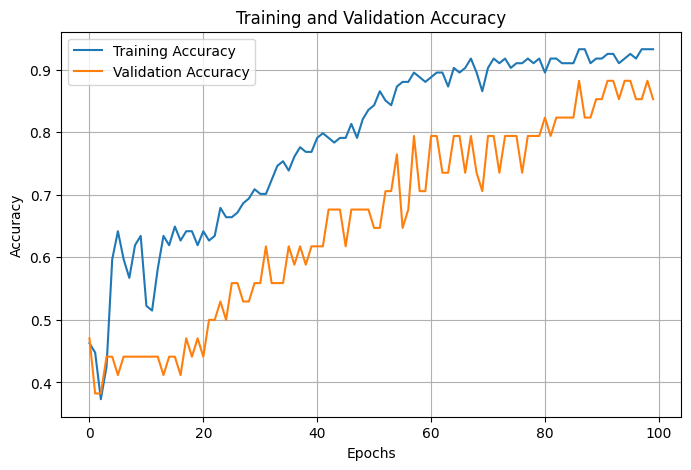

In [54]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

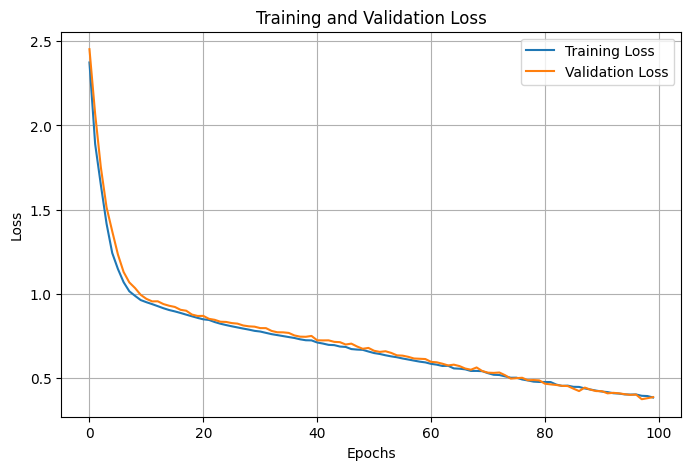

In [55]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show

In [56]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8571 - loss: 0.4592
Test Loss: 0.45917803049087524
Test Accuracy: 0.8571428656578064


In [57]:
y_prob = model.predict(X_test,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
[[0.6194828  0.21671034 0.16380683]
 [0.408615   0.03739302 0.553992  ]
 [0.6031374  0.28598744 0.11087522]
 [0.20284288 0.02438822 0.7727689 ]
 [0.12212509 0.8670394  0.01083545]]


In [58]:
y_pred = np.argmax(y_prob,axis=1)
print("Predicted Encoded Classes:")
print(y_pred[:10])

Predicted Encoded Classes:
[0 2 0 2 1 2 1 1 1 1]


In [59]:
y_pred_original = y_pred+1
y_test_original=y_test+1
print("Predicted Classes:")
print(y_pred_original[:10])

Predicted Classes:
[1 3 1 3 2 3 2 2 2 2]


In [60]:
comparison = pd.DataFrame({'Actual': y_test_original, 'Predicted': y_pred_original})
print(comparison.head(10))

     Actual  Predicted
2         1          1
167       3          3
137       2          1
175       3          3
130       2          2
141       3          3
114       2          2
51        1          2
84        2          2
110       2          2


In [61]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy:", accuracy)

Accuracy: 0.8571428571428571


In [62]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')
print("Precision:", precision)

Precision: 0.8660714285714286


In [63]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')
print("Recall:", recall)

Recall: 0.8571428571428571


In [64]:
f1_score = f1_score(y_test_original, y_pred_original, average='weighted')
print("F1 Score:", f1_score)

F1 Score: 0.8584859584859585


In [65]:
metric = classification_report(y_test_original, y_pred_original)
print("Classification Report:")
print(metric)

Classification Report:
              precision    recall  f1-score   support

           1       0.79      0.79      0.79        14
           2       0.81      0.93      0.87        14
           3       1.00      0.86      0.92        14

    accuracy                           0.86        42
   macro avg       0.87      0.86      0.86        42
weighted avg       0.87      0.86      0.86        42



In [66]:
cm = confusion_matrix(y_test_original, y_pred_original)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[11  3  0]
 [ 1 13  0]
 [ 2  0 12]]


<function matplotlib.pyplot.show(close=None, block=None)>

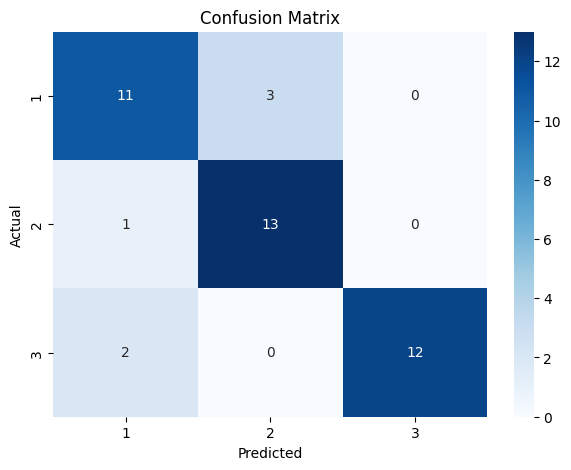

In [67]:
plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y_original.unique()),
    yticklabels=sorted(y_original.unique())
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show